# Veri Seti ve Gerçek Etiketler — Nesli

- 6 bağımsız görüntü: **G1–G2 geliştirme**, **K1–K4 kontrol**. Dönüştürülmüş kopya bağımsız örnek sayılmaz.
- Doğru sınıf, yöntemler çalıştırılmadan **önce** elle belirlenir: başta baret / baret var, başta değil / baret yok / belirsiz.
- Baş bölgesi ve gerçek baret kutuları fareyle elle çizilir (`betikler/kutu_ciz.py`). Görünmeyen baş için etiket uydurulmaz.

In [1]:
from pathlib import Path
import sys
KOK = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "kaynak" / "analiz.py").is_file())
sys.path.insert(0, str(KOK))

import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from kaynak.veri import ayarlari_oku, veri_setini_oku, goruntu_oku, maske_oku
from kaynak.analiz import analiz_et
from kaynak.gorsel import bgr2rgb, kutulari_ciz, maske_bindir
ayarlar = ayarlari_oku()
kayitlar = veri_setini_oku()
pd.set_option("display.max_colwidth", 80)
print("Görüntüler:", ", ".join(f"{k['kimlik']} ({k['bolum']})" for k in kayitlar))

Görüntüler: G1 (gelistirme), G2 (gelistirme), K1 (kontrol), K2 (kontrol), K3 (kontrol), K4 (kontrol)


## 1. Kaynak listesi

In [2]:
pd.DataFrame(kayitlar)[["kimlik", "bolum", "genislik", "yukseklik", "kosul", "kaynak_url", "lisans"]]

,kimlik,bolum,genislik,yukseklik,kosul,kaynak_url,lisans
0,G1,gelistirme,1280,853,"Gün ışığı; sarı baret başta, yüz net görünür (normal ışık)",https://www.pexels.com/photo/man-in-black-crew-neck-t-shirt-wearing-yellow-h...,"Pexels Lisansı (ücretsiz kullanım, atıf zorunlu değil; https://www.pexels.co..."
1,G2,gelistirme,256,256,"Gün ışığı; baş görünür, kumaş şapka, baret yok",https://universe.roboflow.com/ml-pzfty/chv-dataset,CC BY 4.0
2,K1,kontrol,1280,853,"Loş, soğuk mavi iç mekân ışığı; sarı baret başta; sarı-yeşil reflektif yelek",https://www.pexels.com/photo/construction-worker-with-safety-gear-in-industr...,"Pexels Lisansı (ücretsiz kullanım, atıf zorunlu değil; https://www.pexels.co..."
3,K2,kontrol,2121,1414,Uzak; küçük baş ve baret,https://universe.roboflow.com/ml-pzfty/chv-dataset,CC BY 4.0
4,K3,kontrol,1280,853,"Gün ışığı; başı açık işçi (kumaş şapka), sarı-turuncu iş makinesi (aynı renk...",https://www.pexels.com/photo/photo-of-a-man-leaning-on-construction-machine-...,"Pexels Lisansı (ücretsiz kullanım, atıf zorunlu değil; https://www.pexels.co..."
5,K4,kontrol,1280,853,"Gün ışığı; sarı baret elde, başı açık ve görünür",https://www.pexels.com/photo/man-in-black-shirt-holding-yellow-hard-hat-8961...,"Pexels Lisansı (ücretsiz kullanım, atıf zorunlu değil; https://www.pexels.co..."


## 2. Önceden belirlenen sınıflar ve gerekçeler

In [3]:
pd.DataFrame(kayitlar)[["kimlik", "bolum", "dogru_sinif", "gerekce", "bas_roi", "baret_kutulari"]]

,kimlik,bolum,dogru_sinif,gerekce,bas_roi,baret_kutulari
0,G1,gelistirme,basta_baret,Gün ışığında sarı baret kişinin başında; yüz ve baret net görünür.,"[388, 70, 655, 424]","[[397, 85, 646, 253]]"
1,G2,gelistirme,baret_yok,Hedef kişi sağdaki çalışan: başı görünür ve gri kumaş şapka takıyor; kumaş ş...,"[164, 7, 193, 36]",[]
2,K1,kontrol,basta_baret,"Sarı baret kişinin başında; sahne loş ve soğuk mavi ışıkla aydınlatılmış, ba...","[476, 104, 733, 376]","[[523, 111, 735, 272]]"
3,K2,kontrol,basta_baret,Görüntü merkezine en yakın çalışan başında sarı baret taşır. Diğer uzaktaki ...,"[1093, 858, 1136, 909]","[[1094, 859, 1135, 908], [1633, 963, 1658, 1005]]"
4,K3,kontrol,baret_yok,"Hedef kişinin başı ve yüzü görünür; başında kırmızı kumaş şapka var, baret y...","[870, 212, 1013, 375]",[]
5,K4,kontrol,baret_var_basta_degil,Kişinin başı açık ve görünür; sarı baret elde tutuluyor. Yönerge 3a-ii ve K-...,"[472, 20, 1113, 574]","[[4, 313, 425, 852]]"


## 3. Etiketlerin görüntü üzerinde kontrolü
Yeşil: elle çizilmiş baret kutusu · Gri: elle çizilmiş baş ROI

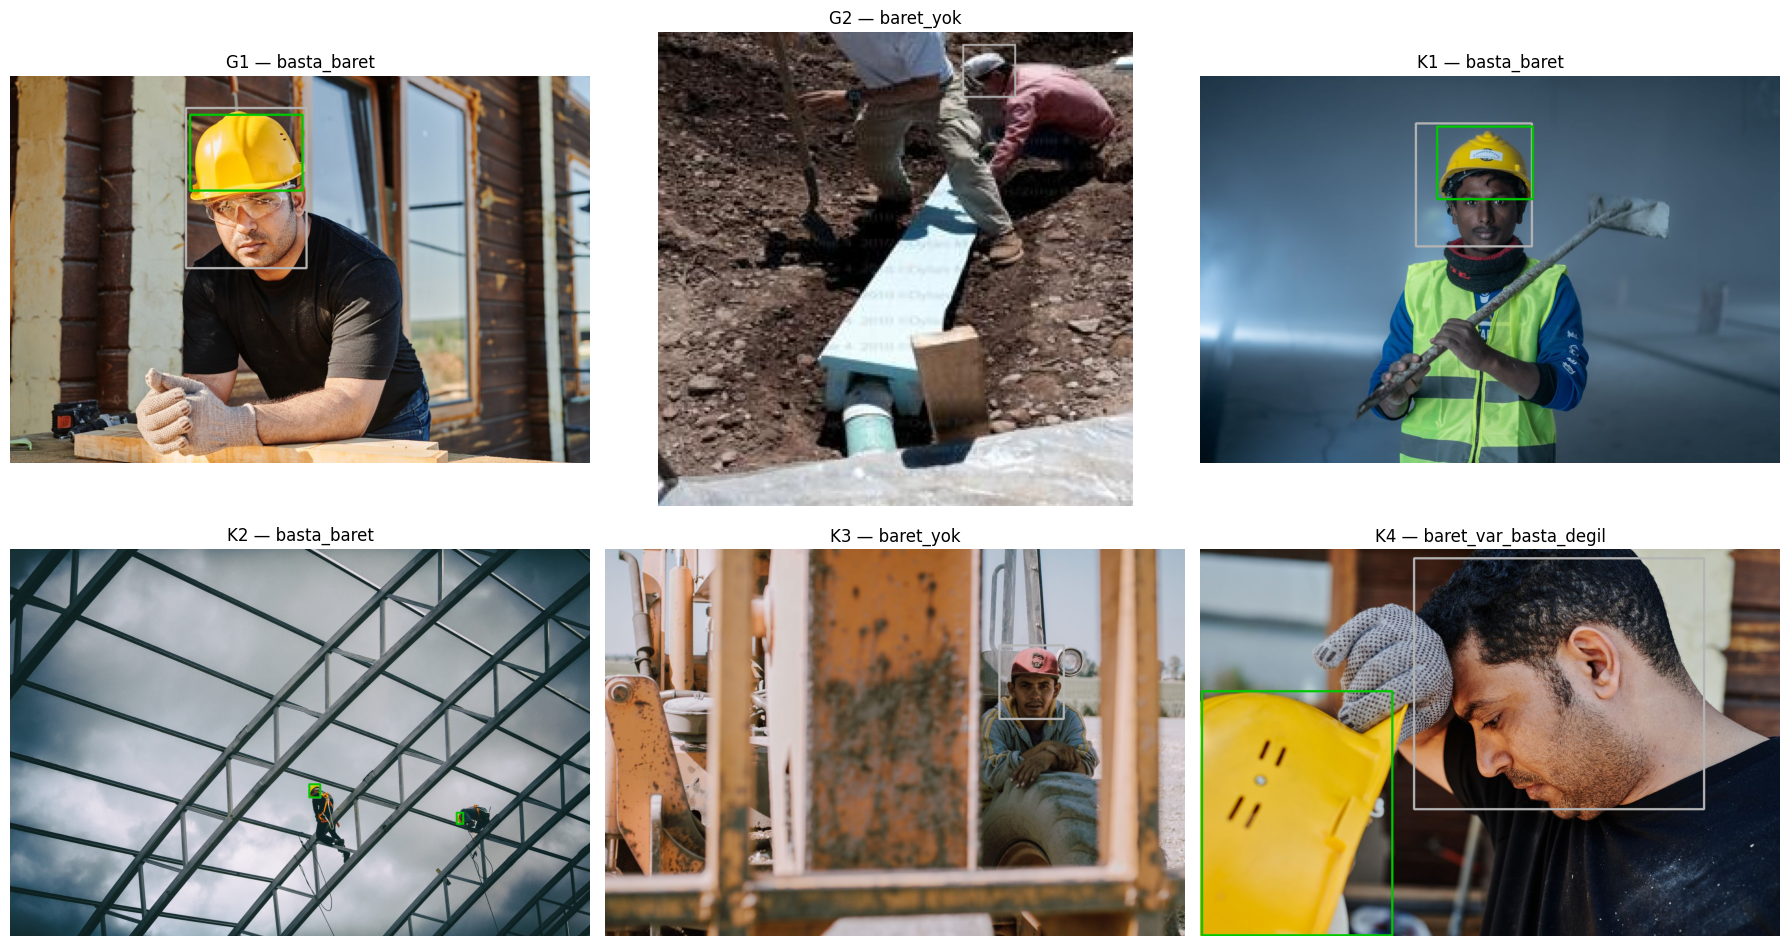

In [4]:
fig, eksen = plt.subplots(2, 3, figsize=(18, 10))
for e, k in zip(eksen.ravel(), kayitlar):
    g = goruntu_oku(k["dosya"])
    m = maske_oku(k["kimlik"], "baret")
    if m is not None:
        g = maske_bindir(g, m)
    g = kutulari_ciz(g, [], k["baret_kutulari"], {"eslesmeler": []}, k["bas_roi"])
    e.imshow(bgr2rgb(g)); e.set_title(f"{k['kimlik']} — {k['dogru_sinif']}"); e.axis("off")
plt.tight_layout(); plt.show()

## 4. Belirsizlik notu
Baş görünmeyen ya da karar için kanıtın yetersiz olduğu görüntülerde sınıf **belirsiz** seçilir; örtülü baş "baret yok" diye etiketlenmez.